# 01 Normalization and PCA of Bulk RNA-seq using PyDESeq
<hr style="border:2px solid black"> </hr>

## 1 - Description

This notebook checks a bulk RNA-seq gene-count matrix and its sample metadata, estimates normalization size factors with PyDESeq, and explores relationships among samples using PCA and a sample-distancee heatmap.

_____

## 2 - Setup and package installation

In [1]:
# Import libraries

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from scipy.spatial.distance import pdist, squareform
from pydeseq2.dds import DeseqDataSet
import yaml

In [2]:
# Set project paths by locating the project root, and
# loading the config.yaml, and defining helper functions
# to resolve the paths and create output directories automatically

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "config.yaml").is_file():
     PROJECT_ROOT = PROJECT_ROOT.parents[1]
with open(PROJECT_ROOT / "config.yaml") as file:
     config = yaml.safe_load(file)
def project_path(relative_path):
      return PROJECT_ROOT / relative_path
def output_folder(relative_path):
     folder = project_path(relative_path)
     folder.mkdir(parents=True, exist_ok=True)
     return folder

## 3 - General input
Set the paths to the raw count matrix and matching sample metadata, and choose an output folder. The count matrix must contain one row per gene and one column per sample, apart from the gene identifier column

### 3.1 - Parameter Overview

| Parameter | Description | Options |
|-----------|-------------|---------|
| counts_file | Path to the raw gene-count TSV file | Enter your count matrix file name / path |
| metadata_file | Path to the sample metadata TSV file | Enter your count matrix file name / path |
| output_folder | Folder where the output tables and plots to be saved in | Predetermined |

<h1><center>⬐ Fill in input data here ⬎</center></h1>

In [3]:
counts_file = project_path(config["inputs"]["counts"])
metadata_file = project_path(config["inputs"]["metadata"])


def output_folder(relative_path):
    folder = project_path(relative_path)
    folder.mkdir(parents=True, exist_ok=True)
    return folder

NORMALIZATION_DATA = output_folder(config["normalization"]["data"])
NORMALIZATION_TABLES = output_folder(config["normalization"]["tables"])
NORMALIZATION_FIGURES = output_folder(config["normalization"]["figures"])

QC_TABLES = output_folder(config["quality_control"]["tables"])
QC_FIGURES = output_folder(config["quality_control"]["figures"])

PCA_TABLES = output_folder(config["pca"]["tables"])
PCA_FIGURES = output_folder(config["pca"]["figures"])

DISTANCE_TABLES = output_folder(config["sample_distances"]["tables"])
DISTANCE_FIGURES = output_folder(config["sample_distances"]["figures"])


print("Project root:", PROJECT_ROOT)
print("Counts file exists:", counts_file.exists())
print("Metadata file exists:", metadata_file.exists())

Project root: /Users/anar/Desktop/islet-t2d-project/bulk-rna-project
Counts file exists: True
Metadata file exists: True


____

## 4 - Load count matrix and metadata

In [4]:
# Read the tsv count matrix and sample metadata ints pandas DataFrames

counts = pd.read_csv(counts_file, sep="\t")
metadata = pd.read_csv(metadata_file, sep="\t")

In [5]:
# Check the dimensions of both inputs and preview
# the datasets to check if they were loaded correctly

print("count matrix shape:", counts.shape)
print("metadata shape:", metadata.shape)

display(counts.head())
display(metadata)

count matrix shape: (62754, 8)
metadata shape: (7, 8)


,gene_id,ERR1629982,ERR1629983,ERR1629984,ERR1629985,ERR1629986,ERR1629987,ERR1629988
0,ENSG00000290825.1,0,0,0,0,0,0,0
1,ENSG00000223972.6,0,0,0,0,0,0,0
2,ENSG00000227232.5,40,18,13,29,15,24,19
3,ENSG00000278267.1,10,9,3,6,8,7,5
4,ENSG00000243485.5,0,0,0,0,0,0,0


,sample_id,donor_id,source_donor_id,condition,sex,age,bmi,hba1c
0,ERR1629982,T2D1,HP1504101T2D,T2D,male,57,24.00,7.00%
1,ERR1629983,H6,HP1504901,Non-diabetic,male,23,21.50,5.50%
2,ERR1629984,H3,HP1506401,Non-diabetic,female,48,35.00,5.70%
3,ERR1629985,H4,HP1507101,Non-diabetic,male,22,32.90,5.40%
4,ERR1629986,T2D2,HP1508501T2D,T2D,female,37,39.60,7.30%
5,ERR1629987,T2D3,HP1525301T2D,T2D,male,52,34.36,7.70%
6,ERR1629988,T2D4,HP1526901T2D,T2D,female,55,29.84,7.40%


In [6]:
# Validate required column names, converts gene counts to
# numric values, and inspects data integrity and sample ordering

assert "gene_id" in counts.columns, "Missing 'gene_id' column in the count matrix."
assert "sample_id" in metadata.columns, "Missing 'sample_id' column in the metadata."
assert "condition" in metadata.columns, "Missing 'condition' column in the metadata."

counts = counts.set_index("gene_id").apply(pd.to_numeric, errors='raise')

print("Duplicate gene IDs:", int(counts.index.duplicated().sum()))
print("Duplicate metadata sample IDs:", int(metadata["sample_id"].duplicated().sum()))
print("Missing count values:", int(counts.isnull().sum().sum()))
print("Negative count values:", int((counts < 0).sum().sum()))
print("non-integer count values:", int(((counts % 1) != 0).sum().sum()))

matrix_sample = counts.columns.astype(str).tolist()
metadata_sample = metadata["sample_id"].astype(str).tolist()

print("Matrix sample order:", matrix_sample)
print("Metadata sample order:", metadata_sample)

Duplicate gene IDs: 0
Duplicate metadata sample IDs: 0
Missing count values: 0
Negative count values: 0
non-integer count values: 0
Matrix sample order: ['ERR1629982', 'ERR1629983', 'ERR1629984', 'ERR1629985', 'ERR1629986', 'ERR1629987', 'ERR1629988']
Metadata sample order: ['ERR1629982', 'ERR1629983', 'ERR1629984', 'ERR1629985', 'ERR1629986', 'ERR1629987', 'ERR1629988']


In [7]:
# Stops the workflow if key input checks fail, 
# because invalid counts or mismatched samples
# can lead to incorrect results 

assert not counts.index.duplicated().any(), "Duplicate gene IDs found in the count matrix."
assert not metadata["sample_id"].duplicated().any(), "Metadata sample IDs must be unique."
assert counts.isnull().sum().sum() == 0, "Missing values found in the count matrix."
assert (counts < 0).sum().sum() == 0, "Negative values found in the count matrix."
assert (counts % 1 == 0).all().all(), "Count values must be integers."
assert set(matrix_sample) == set(metadata_sample), "Sample IDs in the count matrix and metadata do not match."

## 5 - Match metadata to count-matrix sample order

In [8]:
# Set sample_id as the metadata index and reorder metadata to match
# to match the count matrix column order exactly

metadata = metadata.set_index("sample_id").loc[matrix_sample].copy()
metadata.index.name = "sample_id"

print("Samples per condition:")
display(metadata["condition"].value_counts().to_frame("n_samples"))

Samples per condition:


,n_samples
condition,
T2D,4
Non-diabetic,3


___

## 6 - Raw-count quality contral

### 6.1 - Parameter Overview

| Parameter | Description | Options |
|-----------|-------------|---------|
| raw_library_size | Total raw counts for each sample | Sum of counts across gene|
| detected_genes | Number of genes with nonzero counts | count > 0 |
| zero_genes | Number of genes with zero counts | count == 0 |

In [9]:
# Calculate basic per-sample QC metrics

raw_library_size = counts.sum(axis=0)
detected_genes = (counts > 0).sum(axis=0)
zero_genes = (counts == 0).sum(axis=0)
display(raw_library_size.rename("raw_library_size").to_frame())
display(detected_genes.rename("detected_genes").to_frame())
display(zero_genes.rename("zero_genes").to_frame())

,raw_library_size
ERR1629982,22430017
ERR1629983,26573078
ERR1629984,24901487
ERR1629985,31479095
ERR1629986,32081732
ERR1629987,21918856
ERR1629988,21988398


,detected_genes
ERR1629982,25174
ERR1629983,25842
ERR1629984,25930
ERR1629985,25915
ERR1629986,26933
ERR1629987,25788
ERR1629988,25430


,zero_genes
ERR1629982,37580
ERR1629983,36912
ERR1629984,36824
ERR1629985,36839
ERR1629986,35821
ERR1629987,36966
ERR1629988,37324


,sample_id,condition,raw_library_size,detected_genes,zero_genes
0,ERR1629982,T2D,22430017,25174,37580
1,ERR1629983,Non-diabetic,26573078,25842,36912
2,ERR1629984,Non-diabetic,24901487,25930,36824
3,ERR1629985,Non-diabetic,31479095,25915,36839
4,ERR1629986,T2D,32081732,26933,35821
5,ERR1629987,T2D,21918856,25788,36966
6,ERR1629988,T2D,21988398,25430,37324


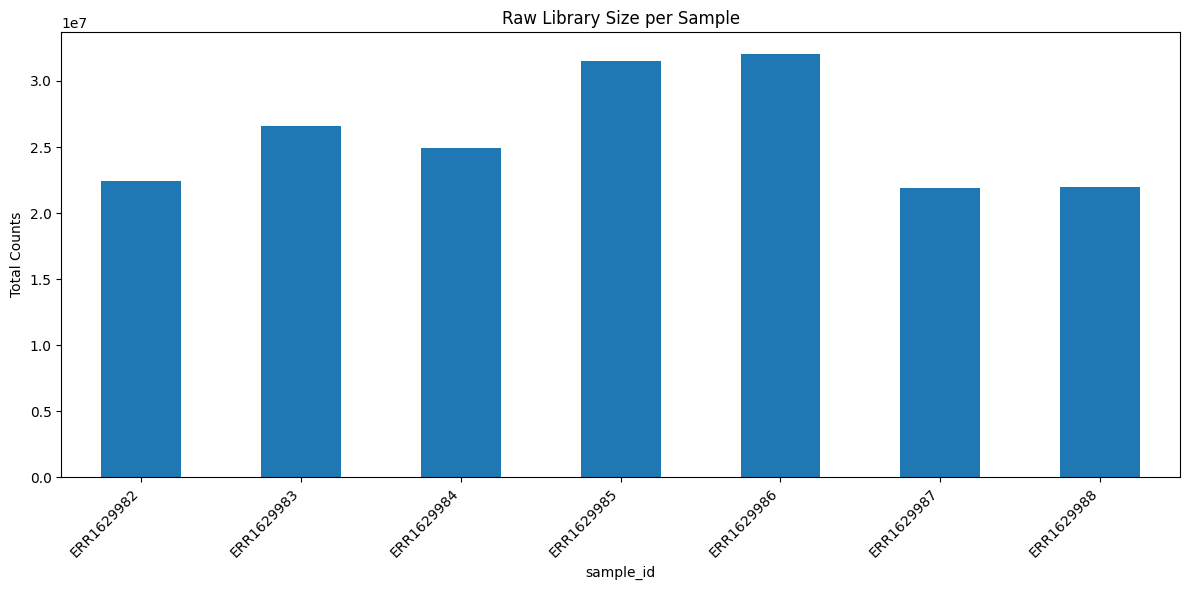

In [10]:
# Combine the QC metrics into one table

qc_metrics = pd.DataFrame({
    "sample_id": matrix_sample,
    "condition": metadata["condition"].values,
    "raw_library_size": raw_library_size.reindex(matrix_sample).values,
    "detected_genes": detected_genes.reindex(matrix_sample).values,
    "zero_genes": zero_genes.reindex(matrix_sample).values
})

# Display and save the table in the assighned folder
display(qc_metrics)
qc_metrics.to_csv(QC_TABLES / "qc_metrics.csv", index=False)

# Plot raw library size to compare sequencing/ count depth across samples
ax = qc_metrics.set_index("sample_id")["raw_library_size"].plot(kind="bar", figsize=(12, 6))
ax.set_title("Raw Library Size per Sample")
ax.set_ylabel("Total Counts")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    QC_FIGURES / "raw_library_size_per_sample.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

____

## 7 - PyDESeq2 Normalization

PyDESeq2 expects samples in rows and genes in columns, so transpose the gene-by-sample count matrix, and raw intger count counts are retained.

Note: do not replace them with normalized values for differential-expression testing 

In [11]:
# Transpose the matrix so samples are in rows and genes are in columns

pydeseq2_counts = counts.T.copy()
pydeseq2_counts.index.name = "sample_id"

In [12]:
# Initialize PyDESeq2 with raw integer counts and condition metadata,
# then estimate sample-specific size factors

dds = DeseqDataSet(counts=pydeseq2_counts, 
                   metadata=metadata, 
                   design_factors="condition",
                   quiet=False,
)

dds.fit_size_factors()

size_factors = pd.Series(
     np.asarray(dds.obsm["size_factors"]).ravel(),
     index=dds.obs_names,
     name="size_factor",
)
normalized_counts = pd.DataFrame(
    np.asarray(dds.layers["normed_counts"]),
    index=dds.obs_names,
    columns=dds.var_names,
)

print("PyDESeq2 size factors:")
display(size_factors.to_frame())
size_factors.to_csv(
    NORMALIZATION_DATA / "pydeseq2_size_factors.csv",
    header=True
)

PyDESeq2 size factors:


Fitting size factors...
... done in 0.01 seconds.



,size_factor
sample_id,
ERR1629982,0.893778
ERR1629983,1.063976
ERR1629984,1.008606
ERR1629985,1.174059
ERR1629986,1.266543
ERR1629987,0.827918
ERR1629988,0.882248


### 7.1 - Parameter Overview

| Parameter | Description | Options |
|-----------|-------------|---------|
| design | metadata variable used in the dataset design | ~condition|
| fit_size_factors() | Estimates sample spicific normalization factors | PyDESeq method |
| size_factors | Estimated scaling factor for each sample |calculated from the count data |
| Normalized_counts | counts adjusted using the estimated size favtors | Retrieved from PyDESeq normalized-count layer |

In [13]:
# Save the normalized count matrix in gene-by-sample layout
# and report the outputs folder location

normalized_counts.T.to_csv(
    NORMALIZATION_DATA / "pydeseq2_normalized_counts.tsv",
    sep="\t",
    index_label="gene_id"
)

print("Normalized counts saved to:", NORMALIZATION_DATA)

Normalized counts saved to: /Users/anar/Desktop/islet-t2d-project/bulk-rna-project/data/processed/bulk_counts/PyDESeq/Normalization


In [14]:
# Apply log2(count + 1) to normalized counts for visualiztion 
# and exploratory analysis. This is not the raw-count input
# for differential-expression testing

log_expression = np.log2(normalized_counts + 1)
log_expression.to_csv(
    NORMALIZATION_DATA / "log2_pydeseq2_normalized_counts.tsv",
    sep="\t",
    index_label="sample_id"
)

### 7.2 - Parameter Overview

| Parameter | Description | Options |
|-----------|-------------|---------|
| Transformation | Formula applied to normalized counts | log2(normalized_counts + 1)|
| pseudocount | Added before taking the logarithm | 1 |

In [15]:
# Compare each sample's total raw count with it's total normalized count
# as a simple normalization diagnostic

library_summary = pd.DataFrame({
"raw_library_size": counts.sum(axis=0).reindex(matrix_sample),
"normalized_count_sum": normalized_counts.sum(axis=1).reindex(matrix_sample),
})

display(library_summary.round(3))
library_summary.to_csv(
    NORMALIZATION_TABLES / "library_totals_before_and_after.csv"
)

,raw_library_size,normalized_count_sum
ERR1629982,22430017,2.509574e+07
ERR1629983,26573078,2.497526e+07
ERR1629984,24901487,2.468901e+07
ERR1629985,31479095,2.681219e+07
ERR1629986,32081732,2.533015e+07
ERR1629987,21918856,2.647466e+07
ERR1629988,21988398,2.492316e+07


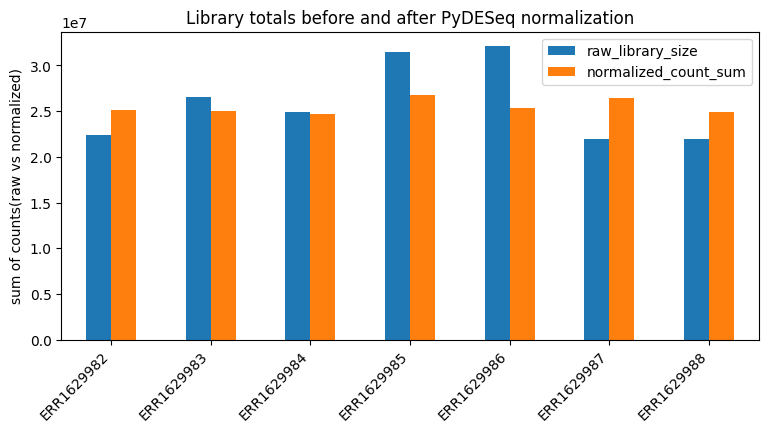

In [16]:
# Plot the raw and normalized library totals
# save the figure for the QC report

library_summary.plot(kind="bar", figsize=(9, 4))
plt.title("Library totals before and after PyDESeq normalization")
plt.ylabel("sum of counts(raw vs normalized)")
plt.xticks(rotation=45, ha="right")
plt.savefig(
    NORMALIZATION_FIGURES / "library_totals.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [17]:
# Define a low-count filter for exploratoty plot:
# retain genes with at least 10 counts in at least two samples

exploration = (counts >= 10).sum(axis=1) >= 2
print("Genes before exploratory filter:", counts.shape[0])
print("Genes retained for PCA/distance plots:", int(exploration.sum()))
print("Genes removed from exploratory plots:", int((~exploration).sum()))

Genes before exploratory filter: 62754
Genes retained for PCA/distance plots: 18822
Genes removed from exploratory plots: 43932


____

## 8 - Principal Components Analysis (PCA)

Summarizes the largest sources of variation across samples into a new axes called principal components, the plots help in revealing sample similarities, group patterns or unusual samples, however it doesn't prove that a difference is caused by T2D

### 8.1 - Parameter Overview

| Parameter | Description | Options |
|-----------|-------------|---------|
| n_componets | Number of components calculated for the plot | 2 |
| PC1 | Component explaining the greatest share of variation | Calculated from input data |
| PC2 | Component explaining the greatest share of variation |Calculated from the input data |
| input data | values used for PCA | Filtered log2-normalized expression|

In [18]:
# Keep only the genes passing the exploratory filter
# and use the log-transformed normalized expression for PCA

pca_input = log_expression.loc[:, exploration].copy()

assert pca_input.shape[0] == len(metadata), "Sample dimensions do not match metadata"

/Users/anar/miniforge3/envs/bulk-rna/lib/python3.10/site-packages/sklearn/utils/extmath.py:340: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/anar/miniforge3/envs/bulk-rna/lib/python3.10/site-packages/sklearn/utils/extmath.py:340: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/anar/miniforge3/envs/bulk-rna/lib/python3.10/site-packages/sklearn/utils/extmath.py:340: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/anar/miniforge3/envs/bulk-rna/lib/python3.10/site-packages/sklearn/utils/extmath.py:341: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/anar/miniforge3/envs/bulk-rna/lib/python3.10/site-packages/sklearn/utils/extmath.py:341: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/anar/miniforge3/envs/bulk-rna/lib/python3.10/site-packages/sklearn/utils/extmath.py:341: RuntimeWarning: invalid value enc

,sample_id,PC1,PC2,condition,donor_id
0,ERR1629982,38.982,8.108,T2D,T2D1
1,ERR1629983,61.728,2.106,Non-diabetic,H6
2,ERR1629984,-38.202,81.339,Non-diabetic,H3
3,ERR1629985,55.019,-9.059,Non-diabetic,H4
4,ERR1629986,-44.456,-9.787,T2D,T2D2
5,ERR1629987,-39.213,-49.090,T2D,T2D3
6,ERR1629988,-33.858,-23.616,T2D,T2D4


PC1 explains 32.5% of variance
PC2 explains 22.1% of variance


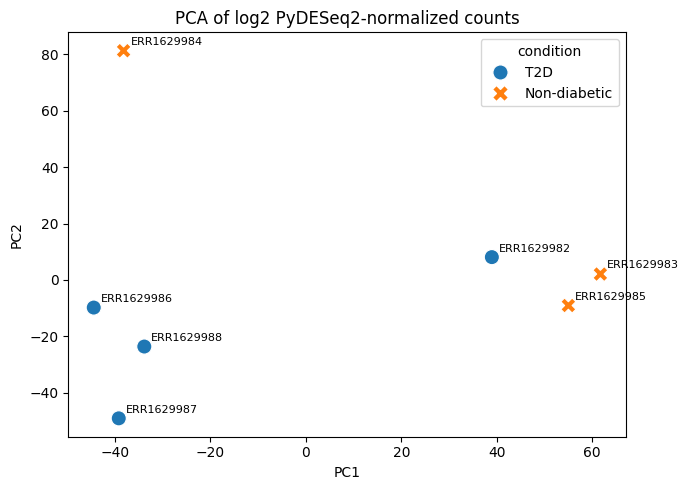

In [19]:
# Fit PCA to summarize major expression variation
# Attach condition/donor labels display explained variance
pca_model = PCA(
    n_components=config["pca"]["n_components"]
)
pca_coordinates = pca_model.fit_transform(pca_input.values)
pca_df = pd.DataFrame(
    pca_coordinates,
    index=pca_input.index,
    columns=["PC1", "PC2"],
).reset_index(names="sample_id")
pca_df = pca_df.merge(metadata.reset_index()[["sample_id", "condition", "donor_id"]], on="sample_id", how="left")

display(pca_df.round(3))

print(f"PC1 explains {pca_model.explained_variance_ratio_[0]*100:.1f}% of variance")
print(f"PC2 explains {pca_model.explained_variance_ratio_[1]*100:.1f}% of variance")

# Save the PCA plot and coordinates 
plt.figure(figsize=(7, 5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="condition", style="condition", s=120)

for _, row in pca_df.iterrows():
    plt.annotate(
        row["sample_id"], 
        (row["PC1"], row["PC2"]), 
    xytext=(5, 4),
    textcoords="offset points", 
    fontsize=8
    )
plt.title("PCA of log2 PyDESeq2-normalized counts")
plt.tight_layout()
plt.savefig(
    PCA_FIGURES / "PCA_bulk_samples.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
pca_df.to_csv(
    PCA_TABLES / "PCA_coordinates.csv",
    index=False
)

___

## 9 - Sample-distance heatmap
Calculates pairwise Euclidean distances between samples using the same transformed expression matrix as PCA, smaller distance indicates silmilar profiles under this metric, and larger distances indicates more different profiles.

sample_id,ERR1629982,ERR1629983,ERR1629984,ERR1629985,ERR1629986,ERR1629987,ERR1629988
sample_id,,,,,,,
ERR1629982,0.00,105.86,129.79,101.75,120.56,126.23,120.80
ERR1629983,105.86,0.00,140.92,100.62,132.23,137.84,123.77
ERR1629984,129.79,140.92,0.00,139.90,118.23,135.86,124.71
ERR1629985,101.75,100.62,139.90,0.00,127.66,127.74,124.88
ERR1629986,120.56,132.23,118.23,127.66,0.00,106.23,93.70
ERR1629987,126.23,137.84,135.86,127.74,106.23,0.00,104.27
ERR1629988,120.80,123.77,124.71,124.88,93.70,104.27,0.00


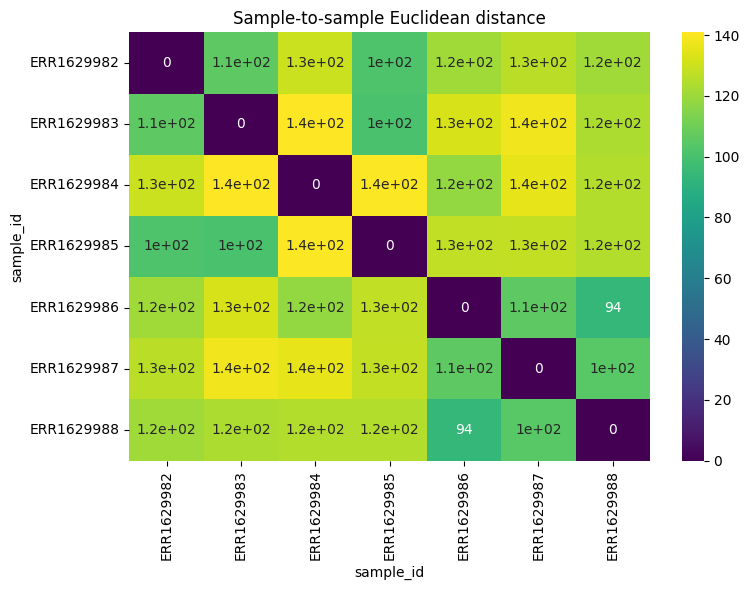

In [20]:
# Claculate pairwise Euclidean distance between samples using the same transformed
# expression matrix 

distance_values = squareform(pdist(pca_input.values, metric="euclidean"))
distance_df = pd.DataFrame(
    distance_values, index=pca_input.index, columns=pca_input.index
)

# Display and save the heatmap and the distance table
display(distance_df.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(distance_df, cmap="viridis", annot=True)
plt.title("Sample-to-sample Euclidean distance")
plt.tight_layout()
plt.savefig(
    DISTANCE_FIGURES / "sample_distance_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
distance_df.to_csv(
    DISTANCE_TABLES / "sample_distance_matrix.tsv",
    sep="\t"
)

___

## 10 - QC and outputs summary

In [21]:
# Summarize key input checks, sample counts, filtering, and normalized settings,
# then list all files generated

summary = {
    "n_genes_input": int(counts.shape[0]),
    "n_samples": int(counts.shape[1]),
    "n_T2D": int((metadata["condition"] == "T2D").sum()),
    "n_non_diabetic": int((metadata["condition"] == "Non-diabetic").sum()),
    "duplicate_gene_ids": int(counts.index.duplicated().sum()),
    "duplicate_metadata_sample_ids": int(pd.Index(metadata.index).duplicated().sum()),
    "missing_count_values": int(counts.isna().sum().sum()),
    "negative_count_values": int((counts < 0).sum().sum()),
    "non_integer_count_values": int(((counts % 1) != 0).sum().sum()),
    "genes_retained_for_exploration": int(exploration.sum()),
    "normalization": "PyDESeq2 fit_size_factors; normalized counts from dds.layers['normed_counts']",
    "visualization_transform": "log2(normalized count + 1)",
}
pd.Series(summary, name="value").to_csv(
    QC_TABLES / "QC_summary.csv",
    header=True
)
display(pd.Series(summary, name="value").to_frame())

,value
n_genes_input,62754
n_samples,7
n_T2D,4
n_non_diabetic,3
duplicate_gene_ids,0
duplicate_metadata_sample_ids,0
missing_count_values,0
negative_count_values,0
non_integer_count_values,0
genes_retained_for_exploration,18822


____

### Expected output files and fogures

- Raw per-sample QC metrics and summary tables
- PyDESeq2 size factors and normalized counts
- Log2-transformed normalized expression values
- Library-size comparison plot
- PCA coordinates and PCA figure
- Sample-distance table and heatmap